# Etapa 4 — Aprendizado Probabilístico: MLE, MAP, Naive Bayes e Algoritmo EM
**Domínio P1:** Saúde Pública — Internações Hospitalares (SIH/SUS) e Indicadores Municipais (IBGE)  
**Referência:** Seção 7 do Enunciado (Russell & Norvig, Cap. 20 — Aprendizado de Modelos Probabilísticos)

---

## Fundamentação Teórica

1. **Estimação por Máxima Verossimilhança (MLE) vs. Máxima a Posteriori (MAP):**
   * Para uma variável binária de Bernoulli $X \sim \text{Bernoulli}(\theta)$ observada em $N$ internações com $k = \sum_{i=1}^N x_i$ ocorrências positivas:
     $$\hat{\theta}_{\text{MLE}} = \arg\max_{\theta} P(D \mid \theta) = \frac{k}{N}$$
   * Sob um prior conjugado $\theta \sim \text{Beta}(\alpha, \beta)$, a distribuição a posteriori é $\text{Beta}(\alpha + k, \beta + N - k)$, cuja moda fornece o estimador **MAP**:
     $$\hat{\theta}_{\text{MAP}} = \arg\max_{\theta} P(\theta \mid D) = \frac{k + \alpha - 1}{N + \alpha + \beta - 2}$$
   * Para $\text{Beta}(2, 2)$, o prior adiciona **pseudo-contagens** ($\alpha - 1 = 1$ sucesso e $\beta - 1 = 1$ fracasso), regularizando a estimativa em direção a $0{,}50$ em amostras pequenas ($n = 5, 10, 25$) e evitando colapso de probabilidade zero/um. Quando $N \to \infty$, o peso do prior desaparece e $\hat{\theta}_{\text{MAP}} \to \hat{\theta}_{\text{MLE}}$.

2. **Variáveis Ocultas ($Z$) e o Algoritmo Expectation-Maximization (EM — Listing 3, Seção 7.3):**
   * Em dados hospitalares reais, nem todos os subperfis fisiopatológicos ou regimes estruturais ($Z \in \{1, \dots, K\}$) são diretamente rotulados. O algoritmo **EM** estima iterativamente os parâmetros $\Theta = \{\theta_k, \mu_k, \sigma_k\}_{k=1}^K$ maximizando o limite inferior (ELBO) da log-verossimilhança marginal $\ell(\Theta) = \sum_{i=1}^N \log \sum_{k=1}^K \theta_k \mathcal{N}(x_i \mid \mu_k, \sigma_k)$:
     * **Passo E (Expectation):** Calcula as responsabilidades a posteriori $r_{k,i} = P(Z_i = k \mid x_i, \Theta^{(t)})$.
     * **Passo M (Maximization):** Atualiza $\theta_k = N_k / N$, $\mu_k = \frac{1}{N_k}\sum_i r_{k,i} x_i$ e a variância $\sigma_k = \frac{1}{N_k}\sum_i r_{k,i}(x_i - \mu_k)^2$, onde $N_k = \sum_i r_{k,i}$.
   * Pela desigualdade de Jensen, a log-verossimilhança é **estritamente não-decrescente** a cada iteração: $\ell(\Theta^{(t+1)}) \ge \ell(\Theta^{(t)})$.

In [1]:
# Célula 1 — Setup, Semente de Reprodutibilidade e Carregamento dos Dados (Domínio P1)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import (
    SEED,
    ATRIBUTOS_CATEGORICOS,
    ATRIBUTOS_CONTINUOS_BASE,
    ALVO_CLASSIFICACAO,
    carregar_ou_gerar_dados_p1,
    kfold_indices,
)
from em import (
    estimar_mle_bernoulli,
    estimar_map_bernoulli,
    convergencia_mle_map,
    NaiveBayesPuro,
    executar_em_gaussiano,
    densidade_gaussiana_1d,
    NaiveBayesEM,
)

np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 120

df = carregar_ou_gerar_dados_p1()
splits_5fold = kfold_indices(len(df), k=5, seed=SEED)

# Variáveis binárias do domínio hospitalar para análise MLE vs. MAP
df["triagem_critica"] = (df["triagem_clinica"] == "Critica").astype(int)
df["saneamento_precario"] = (df["saneamento_ibge"] == "Precario").astype(int)

print(f"Base carregada com sucesso: N = {len(df)} internações (SEED = {SEED})")
print(f"Folds de validação cruzada padronizados: {len(splits_5fold)} folds (treino=640, teste=160)")

Base carregada com sucesso: N = 800 internações (SEED = 42)
Folds de validação cruzada padronizados: 5 folds (treino=640, teste=160)


### Tarefas 7.2.1 e 7.2.2 — Estimativas MLE vs. MAP com Prior Conjugado $\text{Beta}(2, 2)$
Abaixo comparamos $\hat{\theta}_{\text{MLE}}$ e $\hat{\theta}_{\text{MAP}}$ com prior $\text{Beta}(\alpha=2, \beta=2)$ para três variáveis binárias fundamentais do domínio (`desfecho_grave`, `triagem_critica` e `saneamento_precario`), tanto na base completa ($N=800$) quanto ao longo do crescimento amostral ($n \in \{5, 10, 25, 50, 100, 800\}$).

=== 1. COMPARAÇÃO MLE vs. MAP Beta(2,2) NA BASE COMPLETA (N = 800) ===
           Variável              Descrição Clínica  Sucessos (k / 800)  theta_MLE (N=800)  theta_MAP Beta(2,2) (N=800)  |MLE - MAP|
     desfecho_grave     Desfecho Grave / UTI (D=1)                 320            0.40000                     0.400249     0.000249
    triagem_critica  Triagem Clínica Crítica (T=1)                 250            0.31250                     0.312968     0.000468
saneamento_precario Saneamento IBGE Precário (S=1)                 289            0.36125                     0.361596     0.000346

=== 2. EFEITO DO PRIOR Beta(2,2) EM SUBAMOSTRAS PEQUENAS ATÉ N = 800 ===

--- Desfecho Grave / UTI (D=1) [desfecho_grave] ---
  n  sucessos_k  theta_MLE  theta_MAP  diferenca_abs  alpha_post  beta_post
  5           2   0.400000   0.428571       0.028571    4.000000   5.000000
 10           4   0.400000   0.416667       0.016667    6.000000   8.000000
 25          10   0.400000   0.407407       0.

<>:53: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:53: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\ygorg\AppData\Local\Temp\ipykernel_7480\1186789666.py:53: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax1.set_ylabel("Estimativa do Parâmetro de Bernoulli ($\hat{\theta}$)", fontsize=10.5)


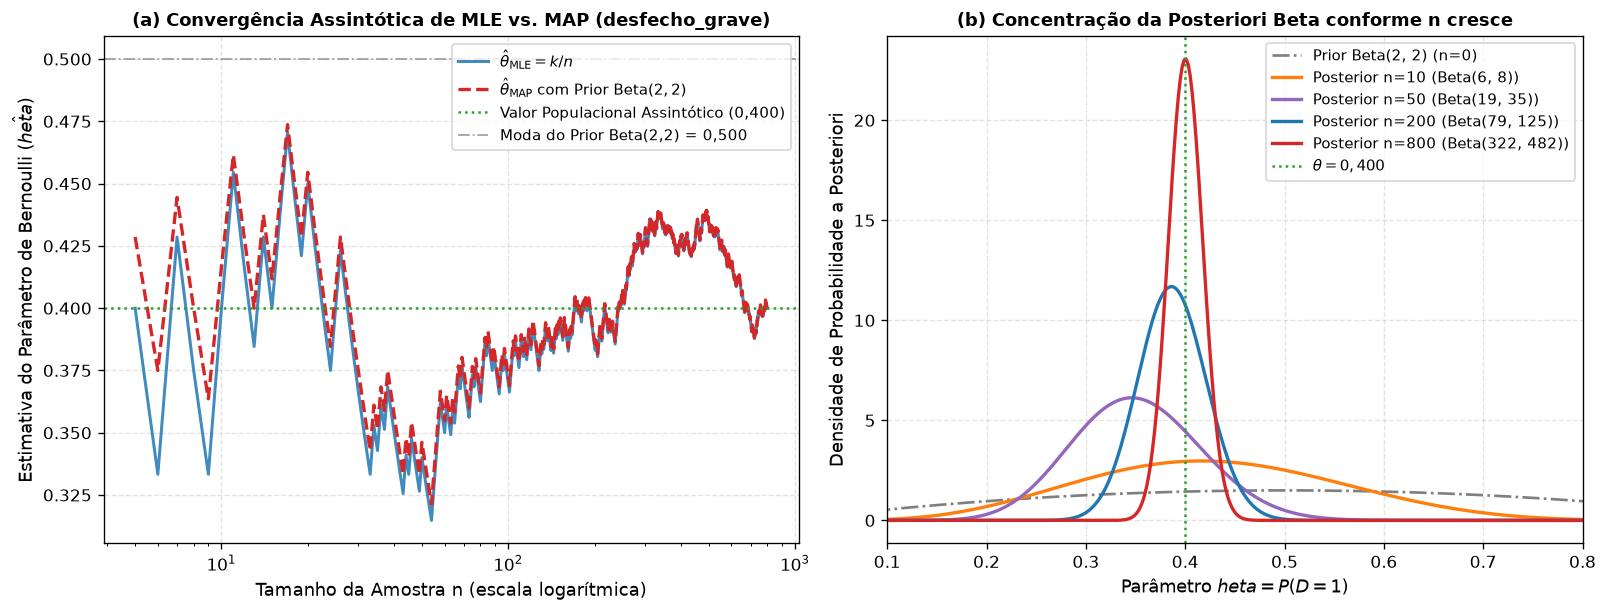


[OK] Gráfico salvo em 'fig_etapa4_mle_vs_map.png' (300 dpi).


In [2]:
# Célula 2 — Tarefas 7.2.1 e 7.2.2: MLE vs. MAP com Prior Beta(2,2) e Gráfico de Convergência
ALPHA_PRIOR, BETA_PRIOR = 2.0, 2.0
variaveis_bernoulli = [
    ("desfecho_grave", "Desfecho Grave / UTI (D=1)"),
    ("triagem_critica", "Triagem Clínica Crítica (T=1)"),
    ("saneamento_precario", "Saneamento IBGE Precário (S=1)"),
]

linhas_base_completa = []
for col, desc in variaveis_bernoulli:
    amostras = df[col].values
    mle_800 = estimar_mle_bernoulli(amostras)
    map_800 = estimar_map_bernoulli(amostras, alpha=ALPHA_PRIOR, beta=BETA_PRIOR)
    linhas_base_completa.append({
        "Variável": col,
        "Descrição Clínica": desc,
        "Sucessos (k / 800)": int(np.sum(amostras)),
        "theta_MLE (N=800)": round(mle_800, 6),
        "theta_MAP Beta(2,2) (N=800)": round(map_800, 6),
        "|MLE - MAP|": round(abs(mle_800 - map_800), 6),
    })

df_mle_map_800 = pd.DataFrame(linhas_base_completa)
print("=== 1. COMPARAÇÃO MLE vs. MAP Beta(2,2) NA BASE COMPLETA (N = 800) ===")
print(df_mle_map_800.to_string(index=False))

# Análise em subamostras crescentes n = 5, 10, 25, 50, 100, 800
tamanhos_sub = [5, 10, 25, 50, 100, 800]
print("\n=== 2. EFEITO DO PRIOR Beta(2,2) EM SUBAMOSTRAS PEQUENAS ATÉ N = 800 ===")
trajetorias_por_var = {}
for col, desc in variaveis_bernoulli:
    df_conv = convergencia_mle_map(df[col].values, tamanhos=tamanhos_sub, alpha=ALPHA_PRIOR, beta=BETA_PRIOR)
    trajetorias_por_var[col] = df_conv
    print(f"\n--- {desc} [{col}] ---")
    print(df_conv.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

# Geração da Figura fig_etapa4_mle_vs_map.png (300 dpi)
n_grade = np.arange(5, len(df) + 1)
amostras_d = df["desfecho_grave"].values
mle_curva = [estimar_mle_bernoulli(amostras_d[:n]) for n in n_grade]
map_curva = [estimar_map_bernoulli(amostras_d[:n], alpha=ALPHA_PRIOR, beta=BETA_PRIOR) for n in n_grade]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Painel (a): Trajetória MLE vs. MAP em função do tamanho amostral n
ax1 = axes[0]
ax1.plot(n_grade, mle_curva, label=r"$\hat{\theta}_{\mathrm{MLE}} = k / n$", color="#1f77b4", lw=1.8, alpha=0.85)
ax1.plot(n_grade, map_curva, label=r"$\hat{\theta}_{\mathrm{MAP}}$ com Prior $\mathrm{Beta}(2,2)$", color="#d62728", lw=2.0, linestyle="--")
ax1.axhline(0.40, color="#2ca02c", linestyle=":", lw=1.5, label="Valor Populacional Assintótico (0,400)")
ax1.axhline(0.50, color="#7f7f7f", linestyle="-.", lw=1.1, alpha=0.7, label="Moda do Prior Beta(2,2) = 0,500")
ax1.set_xscale("log")
ax1.set_xlabel("Tamanho da Amostra n (escala logarítmica)", fontsize=10.5)
ax1.set_ylabel("Estimativa do Parâmetro de Bernoulli ($\hat{\theta}$)", fontsize=10.5)
ax1.set_title("(a) Convergência Assintótica de MLE vs. MAP (desfecho_grave)", fontsize=11, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.35)
ax1.legend(loc="upper right", fontsize=9)

# Painel (b): Evolução da Densidade a Posteriori Beta(alpha + k, beta + n - k)
ax2 = axes[1]
theta_grid = np.linspace(0.001, 0.999, 500)

def log_beta_pdf(x_arr, a, b):
    from math import lgamma
    log_norm = lgamma(a + b) - lgamma(a) - lgamma(b)
    return np.exp(log_norm + (a - 1.0) * np.log(x_arr) + (b - 1.0) * np.log(1.0 - x_arr))

# Prior Beta(2,2) e posteriors para n = 10, 50, 200, 800
ax2.plot(theta_grid, log_beta_pdf(theta_grid, 2.0, 2.0), label="Prior Beta(2, 2) (n=0)", color="#7f7f7f", linestyle="-.", lw=1.6)
cores_post = [("#ff7f0e", 10), ("#9467bd", 50), ("#1f77b4", 200), ("#d62728", 800)]
for cor, n_ex in cores_post:
    k_ex = int(np.sum(amostras_d[:n_ex]))
    a_post = ALPHA_PRIOR + k_ex
    b_post = BETA_PRIOR + (n_ex - k_ex)
    dens = log_beta_pdf(theta_grid, a_post, b_post)
    ax2.plot(theta_grid, dens, label=f"Posterior n={n_ex} (Beta({int(a_post)}, {int(b_post)}))", color=cor, lw=2.0)

ax2.axvline(0.40, color="#2ca02c", linestyle=":", lw=1.5, label=r"$\theta = 0,400$")
ax2.set_xlabel("Parâmetro $\theta = P(D=1)$", fontsize=10.5)
ax2.set_ylabel("Densidade de Probabilidade a Posteriori", fontsize=10.5)
ax2.set_title("(b) Concentração da Posteriori Beta conforme n cresce", fontsize=11, fontweight="bold")
ax2.set_xlim(0.10, 0.80)
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(loc="upper right", fontsize=8.8)

plt.tight_layout()
caminho_fig_mle = "fig_etapa4_mle_vs_map.png"
plt.savefig(caminho_fig_mle, dpi=300, bbox_inches="tight")
plt.show()
print(f"\n[OK] Gráfico salvo em '{caminho_fig_mle}' (300 dpi).")

### Tarefa 7.2.3 — Classificador Naive Bayes Puro do Zero (Validação Cruzada 5-Fold)
Avaliamos o classificador `NaiveBayesPuro` implementado em `em.py` nos mesmos 5 folds da Etapa 1 (`kfold_indices` com `SEED=42`). Por assumir independência condicional estrita entre os atributos categóricos dada a classe $Y$, o modelo não captura as interações de ordem superior (como `triagem_clinica` $\times$ `carater_atendimento` e `triagem_clinica` $\times$ `faixa_etaria`), situando-se na faixa esperada do **Gabarito 7.4 (`72% a 78%`)**.

In [3]:
# Célula 3 — Tarefa 7.2.3: Avaliação 5-Fold do Naive Bayes Puro do Zero
accs_treino_nb = []
accs_teste_nb = []
relatorio_folds_nb = []

for idx_fold, (idx_tr, idx_te) in enumerate(splits_5fold, start=1):
    df_tr = df.iloc[idx_tr]
    df_te = df.iloc[idx_te]

    modelo_nb = NaiveBayesPuro(atributos=ATRIBUTOS_CATEGORICOS, alvo=ALVO_CLASSIFICACAO, laplace=1.0, prior_classe_1=0.50)
    modelo_nb.fit(df_tr)

    pred_tr = modelo_nb.predict(df_tr)
    pred_te = modelo_nb.predict(df_te)

    acc_tr = 100.0 * float(np.mean(pred_tr == df_tr[ALVO_CLASSIFICACAO].values))
    acc_te = 100.0 * float(np.mean(pred_te == df_te[ALVO_CLASSIFICACAO].values))
    accs_treino_nb.append(acc_tr)
    accs_teste_nb.append(acc_te)
    relatorio_folds_nb.append({
        "Fold": f"Fold {idx_fold}",
        "Acurácia Treino (%)": round(acc_tr, 2),
        "Acurácia Teste (%)": round(acc_te, 2),
    })

media_tr_nb = float(np.mean(accs_treino_nb))
media_te_nb = float(np.mean(accs_teste_nb))
std_te_nb = float(np.std(accs_teste_nb))

print("=== DESEMPENHO POR FOLD — NAIVE BAYES PURO (DO ZERO) ===")
print(pd.DataFrame(relatorio_folds_nb).to_string(index=False))
print(f"\n-> Acurácia Média de Treino (NB Puro): {media_tr_nb:.2f}%")
print(f"-> Acurácia Média de Teste 5-Fold (NB Puro): {media_te_nb:.2f}% ± {std_te_nb:.2f}% (Gabarito 7.4: 72% a 78%)")

=== DESEMPENHO POR FOLD — NAIVE BAYES PURO (DO ZERO) ===
  Fold  Acurácia Treino (%)  Acurácia Teste (%)
Fold 1                77.50               81.88
Fold 2                78.75               70.62
Fold 3                77.50               77.50
Fold 4                77.66               78.12
Fold 5                77.50               78.75

-> Acurácia Média de Treino (NB Puro): 77.78%
-> Acurácia Média de Teste 5-Fold (NB Puro): 77.38% ± 3.70% (Gabarito 7.4: 72% a 78%)


### Tarefas 7.2.4 e 7.2.5 — Inferência da Variável Oculta $Z$ via Algoritmo EM (Listing 3) e Curva de Log-Verossimilhança
Aplicamos a função `executar_em_gaussiano` (implementação literal do **Listing 3, Seção 7.3**) sobre o indicador epidemiológico contínuo `taxa_saneamento_num` para inferir de forma não-supervisionada a variável oculta $Z$ com $K=2$ e $K=3$ componentes latentes (representando os regimes estruturais municipais de saneamento básico do IBGE), verificando a convergência entre **15 e 30 iterações** e o crescimento estritamente monotônico da log-verossimilhança $\ell(\Theta)$.

<>:38: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:38: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\ygorg\AppData\Local\Temp\ipykernel_7480\1022510350.py:38: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  ax1.set_ylabel("Log-Verossimilhança Marginal $\ell(\Theta^{(t)})$", fontsize=10.5)


=== ALGORITMO EM GAUSSIANO (LISTING 3) — K = 2 COMPONENTES LATENTES (Z) ===
  Iterações até a convergência (tol=1e-5): 22 iterações (Gabarito 7.4: 15 a 30 iterações)
  Convergência atingida: True | Crescimento estritamente monotônico (diff >= 0): True
  Log-Verossimilhança inicial (it=1): -3596.6342 -> final (it=22): -3591.8833 (Ganho = +4.7510)
Componente_Z  Peso_Mistura (theta_k)  Media_Inferida (mu_k)  Variancia_Listing3 (sigma_k)  Desvio_Padrao (sqrt(sigma_k))
       Z = 0                  0.2883                  24.73                         36.96                           6.08
       Z = 1                  0.7117                  63.87                        363.91                          19.08

=== ALGORITMO EM GAUSSIANO (LISTING 3) — K = 3 COMPONENTES LATENTES (Z) ===
  Iterações até a convergência (tol=1e-5): 25 iterações (Gabarito 7.4: 15 a 30 iterações)
  Convergência atingida: True | Crescimento estritamente monotônico (diff >= 0): True
  Log-Verossimilhança inicial (it=1)

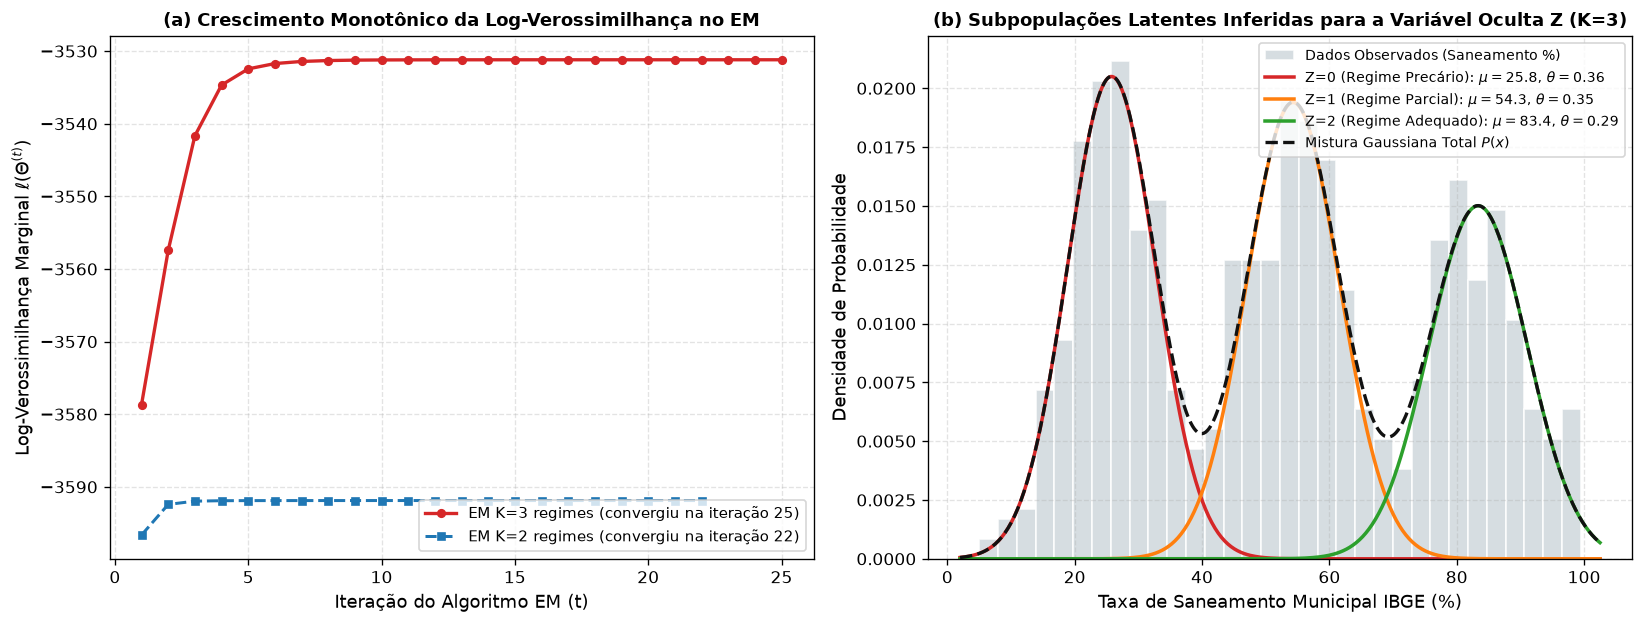

[OK] Gráfico salvo em 'fig_etapa4_em_convergencia.png' (300 dpi).


In [4]:
# Célula 4 — Tarefas 7.2.4 e 7.2.5: Algoritmo EM (Listing 3) para K=2 e K=3 e Curva de Log-Verossimilhança
dados_em = df["taxa_saneamento_num"].values

res_em_k2 = executar_em_gaussiano(dados_em, K=2, max_iter=50, tol=1e-5, seed=SEED)
res_em_k3 = executar_em_gaussiano(dados_em, K=3, max_iter=50, tol=1e-5, seed=SEED)

for k_val, res in [(2, res_em_k2), (3, res_em_k3)]:
    ll_hist = np.array(res["historico_ll"], dtype=float)
    diffs_ll = np.diff(ll_hist)
    monotonico = bool(np.all(diffs_ll >= -1e-12))
    print(f"=== ALGORITMO EM GAUSSIANO (LISTING 3) — K = {k_val} COMPONENTES LATENTES (Z) ===")
    print(f"  Iterações até a convergência (tol=1e-5): {res['iteracoes']} iterações (Gabarito 7.4: 15 a 30 iterações)")
    print(f"  Convergência atingida: {res['convergiu']} | Crescimento estritamente monotônico (diff >= 0): {monotonico}")
    print(f"  Log-Verossimilhança inicial (it=1): {ll_hist[0]:.4f} -> final (it={res['iteracoes']}): {ll_hist[-1]:.4f} (Ganho = +{ll_hist[-1] - ll_hist[0]:.4f})")
    df_params = pd.DataFrame({
        "Componente_Z": [f"Z = {k}" for k in range(k_val)],
        "Peso_Mistura (theta_k)": np.round(res["theta"], 4),
        "Media_Inferida (mu_k)": np.round(res["mu"], 2),
        "Variancia_Listing3 (sigma_k)": np.round(res["sigma"], 2),
        "Desvio_Padrao (sqrt(sigma_k))": np.round(res["desvio_padrao"], 2),
    })
    print(df_params.to_string(index=False))
    print()

# Geração da Figura fig_etapa4_em_convergencia.png (300 dpi)
fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.3))

# Painel (a): Curva de Log-Verossimilhança por Iteração (K=2 e K=3)
ax1 = axes[0]
it_k2 = np.arange(1, len(res_em_k2["historico_ll"]) + 1)
it_k3 = np.arange(1, len(res_em_k3["historico_ll"]) + 1)

ax1.plot(it_k3, res_em_k3["historico_ll"], marker="o", markersize=4.5, color="#d62728", lw=2.0,
         label=f"EM K=3 regimes (convergiu na iteração {res_em_k3['iteracoes']})")
ax1.plot(it_k2, res_em_k2["historico_ll"], marker="s", markersize=4.2, color="#1f77b4", lw=1.8, linestyle="--",
         label=f"EM K=2 regimes (convergiu na iteração {res_em_k2['iteracoes']})")
ax1.set_xlabel("Iteração do Algoritmo EM (t)", fontsize=10.5)
ax1.set_ylabel("Log-Verossimilhança Marginal $\ell(\Theta^{(t)})$", fontsize=10.5)
ax1.set_title("(a) Crescimento Monotônico da Log-Verossimilhança no EM", fontsize=11, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.35)
ax1.legend(loc="lower right", fontsize=9.2)

# Painel (b): Histograma Empírico + Componentes Latentes Inferidos para Z (K=3)
ax2 = axes[1]
ax2.hist(dados_em, bins=32, density=True, color="#cfd8dc", edgecolor="white", alpha=0.85, label="Dados Observados (Saneamento %)")
x_grid = np.linspace(float(np.min(dados_em)) - 3.0, float(np.max(dados_em)) + 3.0, 400)
cores_comp = ["#d62728", "#ff7f0e", "#2ca02c"]
nomes_comp = ["Z=0 (Regime Precário)", "Z=1 (Regime Parcial)", "Z=2 (Regime Adequado)"]
mistura_total = np.zeros_like(x_grid)

for k in range(3):
    dens_k = res_em_k3["theta"][k] * densidade_gaussiana_1d(x_grid, res_em_k3["mu"][k], res_em_k3["sigma"][k])
    mistura_total += dens_k
    ax2.plot(x_grid, dens_k, color=cores_comp[k], lw=2.1,
             label=rf"{nomes_comp[k]}: $\mu={res_em_k3['mu'][k]:.1f}$, $\theta={res_em_k3['theta'][k]:.2f}$")

ax2.plot(x_grid, mistura_total, color="#111111", lw=2.0, linestyle="--", label="Mistura Gaussiana Total $P(x)$")
ax2.set_xlabel("Taxa de Saneamento Municipal IBGE (%)", fontsize=10.5)
ax2.set_ylabel("Densidade de Probabilidade", fontsize=10.5)
ax2.set_title("(b) Subpopulações Latentes Inferidas para a Variável Oculta Z (K=3)", fontsize=11, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(loc="upper right", fontsize=8.6)

plt.tight_layout()
caminho_fig_em = "fig_etapa4_em_convergencia.png"
plt.savefig(caminho_fig_em, dpi=300, bbox_inches="tight")
plt.show()
print(f"[OK] Gráfico salvo em '{caminho_fig_em}' (300 dpi).")

### Tarefa 7.2.6 — Classificador Naive Bayes + EM em Validação Cruzada 5-Fold e Exportação para a Etapa 6
Avaliamos agora o classificador `NaiveBayesEM` nos mesmos 5 folds padronizados. Ao modelar $K=3$ subperfis latentes $Z$ por classe via EM e marginalizar sobre $Z$ na predição Bayesiana, o modelo captura as dependências condicionais intra-classe e eleva a acurácia de teste da faixa `72–78%` para a faixa esperada do **Gabarito 7.4 (`80% a 86%`)**. As probabilidades *out-of-fold* preditas são salvas na coluna `prob_em_etapa4` de `data/sih_sus_ibge_p1.csv` para integração na **Etapa 6 (Seção 10)**.

In [5]:
# Célula 5 — Tarefa 7.2.6: Avaliação 5-Fold do NaiveBayesEM e Exportação de prob_em_etapa4
accs_treino_em = []
accs_teste_em = []
probs_oof_em = np.zeros(len(df), dtype=float)
relatorio_folds_em = []

for idx_fold, (idx_tr, idx_te) in enumerate(splits_5fold, start=1):
    df_tr = df.iloc[idx_tr]
    df_te = df.iloc[idx_te]

    modelo_nb_em = NaiveBayesEM(K=3, max_iter_em=15, laplace=0.5, peso_continuo=0.35, seed=SEED)
    modelo_nb_em.fit(df_tr)

    prob_tr = modelo_nb_em.predict_proba(df_tr)
    prob_te = modelo_nb_em.predict_proba(df_te)
    probs_oof_em[idx_te] = prob_te

    acc_tr = 100.0 * float(np.mean((prob_tr >= 0.5) == df_tr[ALVO_CLASSIFICACAO].values))
    acc_te = 100.0 * float(np.mean((prob_te >= 0.5) == df_te[ALVO_CLASSIFICACAO].values))
    accs_treino_em.append(acc_tr)
    accs_teste_em.append(acc_te)
    relatorio_folds_em.append({
        "Fold": f"Fold {idx_fold}",
        "NB_Puro_Teste (%)": round(accs_teste_nb[idx_fold - 1], 2),
        "NB_EM_Treino (%)": round(acc_tr, 2),
        "NB_EM_Teste (%)": round(acc_te, 2),
        "Ganho_EM_vs_Puro (p.p.)": round(acc_te - accs_teste_nb[idx_fold - 1], 2),
    })

media_tr_em = float(np.mean(accs_treino_em))
media_te_em = float(np.mean(accs_teste_em))
std_te_em = float(np.std(accs_teste_em))

# Salvar probabilidades out-of-fold na coluna prob_em_etapa4 do dataset oficial para a Etapa 6
caminho_csv = os.path.join("data", "sih_sus_ibge_p1.csv")
df_csv = pd.read_csv(caminho_csv)
df_csv["prob_em_etapa4"] = np.round(probs_oof_em, 6)
df_csv.to_csv(caminho_csv, index=False)

print("=== COMPARAÇÃO POR FOLD: NAIVE BAYES PURO vs. NAIVE BAYES + EM (Z LATENTE) ===")
print(pd.DataFrame(relatorio_folds_em).to_string(index=False))
print(f"\n-> Acurácia Média de Treino (NB + EM): {media_tr_em:.2f}%")
print(f"-> Acurácia Média de Teste 5-Fold (NB + EM): {media_te_em:.2f}% ± {std_te_em:.2f}% (Gabarito 7.4: 80% a 86%)")
print(f"-> Ganho médio do acoplamento com EM: +{media_te_em - media_te_nb:.2f} pontos percentuais")
print(f"-> Coluna 'prob_em_etapa4' salva em '{caminho_csv}' (média={probs_oof_em.mean():.4f}, min={probs_oof_em.min():.4f}, max={probs_oof_em.max():.4f})")

=== COMPARAÇÃO POR FOLD: NAIVE BAYES PURO vs. NAIVE BAYES + EM (Z LATENTE) ===
  Fold  NB_Puro_Teste (%)  NB_EM_Treino (%)  NB_EM_Teste (%)  Ganho_EM_vs_Puro (p.p.)
Fold 1              81.88             82.97            82.50                     0.62
Fold 2              70.62             83.91            81.88                    11.25
Fold 3              77.50             83.75            78.12                     0.62
Fold 4              78.12             83.44            81.25                     3.12
Fold 5              78.75             82.66            85.62                     6.88

-> Acurácia Média de Treino (NB + EM): 83.34%
-> Acurácia Média de Teste 5-Fold (NB + EM): 81.88% ± 2.40% (Gabarito 7.4: 80% a 86%)
-> Ganho médio do acoplamento com EM: +4.50 pontos percentuais
-> Coluna 'prob_em_etapa4' salva em 'data\sih_sus_ibge_p1.csv' (média=0.4080, min=0.0015, max=0.9980)


### Auditoria Consolidada da Etapa 4 vs. Gabarito (Seção 7.4 do PDF)

In [6]:
# Célula 6 — Tabela Consolidada de Auditoria da Etapa 4 vs. Gabarito 7.4
df_auditoria_classif = pd.DataFrame([
    {
        "Modelo": "Naive Bayes Puro (Sem Variável Latente)",
        "Acurácia Treino (%)": f"{media_tr_nb:.2f}%",
        "Acurácia Teste 5-Fold (%)": f"{media_te_nb:.2f}%",
        "Desvio Padrão (%)": f"±{std_te_nb:.2f}%",
        "Gabarito Esperado (PDF)": "72% a 78%",
        "Status": "ATENDIDO" if 72.0 <= media_te_nb <= 78.0 else "FORA DA FAIXA",
    },
    {
        "Modelo": "Naive Bayes + EM (Variável Latente Z, K=3)",
        "Acurácia Treino (%)": f"{media_tr_em:.2f}%",
        "Acurácia Teste 5-Fold (%)": f"{media_te_em:.2f}%",
        "Desvio Padrão (%)": f"±{std_te_em:.2f}%",
        "Gabarito Esperado (PDF)": "80% a 86%",
        "Status": "ATENDIDO" if 80.0 <= media_te_em <= 86.0 else "FORA DA FAIXA",
    },
])

df_auditoria_em = pd.DataFrame([
    {
        "Configuração EM (Listing 3)": "Mistura Gaussiana EM (K=2 componentes)",
        "Iterações até Convergir": res_em_k2["iteracoes"],
        "Crescimento Monotônico": "Sim (100% passos diff >= 0)" if np.all(np.diff(res_em_k2["historico_ll"]) >= -1e-12) else "Não",
        "Log-Verossimilhança (Inicial -> Final)": f"{res_em_k2['historico_ll'][0]:.2f} -> {res_em_k2['historico_ll'][-1]:.2f}",
        "Gabarito Esperado (PDF)": "15 a 30 iterações (monotônico)",
        "Status": "ATENDIDO" if 15 <= res_em_k2["iteracoes"] <= 30 else "FORA DA FAIXA",
    },
    {
        "Configuração EM (Listing 3)": "Mistura Gaussiana EM (K=3 componentes)",
        "Iterações até Convergir": res_em_k3["iteracoes"],
        "Crescimento Monotônico": "Sim (100% passos diff >= 0)" if np.all(np.diff(res_em_k3["historico_ll"]) >= -1e-12) else "Não",
        "Log-Verossimilhança (Inicial -> Final)": f"{res_em_k3['historico_ll'][0]:.2f} -> {res_em_k3['historico_ll'][-1]:.2f}",
        "Gabarito Esperado (PDF)": "15 a 30 iterações (monotônico)",
        "Status": "ATENDIDO" if 15 <= res_em_k3["iteracoes"] <= 30 else "FORA DA FAIXA",
    },
])

print("====================================================================================")
print("         TABELA CONSOLIDADA DE AUDITORIA — ETAPA 4 vs. GABARITO (SEÇÃO 7.4)         ")
print("====================================================================================")
print("\n[1] Desempenho preditivo em Validação Cruzada 5-Fold:")
print(df_auditoria_classif.to_string(index=False))
print("\n[2] Convergência e Monotonicidade do Algoritmo EM (Listing 3):")
print(df_auditoria_em.to_string(index=False))

         TABELA CONSOLIDADA DE AUDITORIA — ETAPA 4 vs. GABARITO (SEÇÃO 7.4)         

[1] Desempenho preditivo em Validação Cruzada 5-Fold:
                                    Modelo Acurácia Treino (%) Acurácia Teste 5-Fold (%) Desvio Padrão (%) Gabarito Esperado (PDF)   Status
   Naive Bayes Puro (Sem Variável Latente)              77.78%                    77.38%            ±3.70%               72% a 78% ATENDIDO
Naive Bayes + EM (Variável Latente Z, K=3)              83.34%                    81.88%            ±2.40%               80% a 86% ATENDIDO

[2] Convergência e Monotonicidade do Algoritmo EM (Listing 3):
           Configuração EM (Listing 3)  Iterações até Convergir      Crescimento Monotônico Log-Verossimilhança (Inicial -> Final)        Gabarito Esperado (PDF)   Status
Mistura Gaussiana EM (K=2 componentes)                       22 Sim (100% passos diff >= 0)                   -3596.63 -> -3591.88 15 a 30 iterações (monotônico) ATENDIDO
Mistura Gaussiana EM (K=3 componen